# Chapitre 7 - Lab : niveaux d'isolation réels de PostgreSQL

Les cours 2 à 4 ont rejoué les anomalies sur un mini-moteur. Ce lab les reproduit sur un
vrai système, PostgreSQL 16, avec deux connexions (ou plus) qui s'entrelacent : lectures
sales impossibles, lecture biaisée en `READ COMMITTED`, versions MVCC visibles
(`xmin`, `xmax`, `ctid`, pages brutes), mises à jour perdues et leurs remèdes, write skew
des médecins de garde, fantôme de la réservation de salle, échecs de sérialisation
(`SQLSTATE 40001`) et interblocages (`40P01`).

**Démarrer et arrêter PostgreSQL** (depuis la racine du dépôt) :

```bash
docker compose -f docker/transactions/compose.yml -p ddia_transactions up -d
# ... exécuter le notebook ...
docker compose -f docker/transactions/compose.yml -p ddia_transactions down -v
```

Le conteneur écoute sur le port **10832** de l'hôte (utilisateur, mot de passe et base :
`ddia`).

**Plan.**

1. Pas de lecture sale, même en `READ UNCOMMITTED`.
2. Lecture biaisée en `READ COMMITTED`, instantané en `REPEATABLE READ`.
3. MVCC sous le capot : `xmin`, `xmax`, pages brutes et `VACUUM`.
4. Mises à jour perdues : le problème et quatre remèdes, sous charge.
5. Write skew : les médecins de garde.
6. Fantôme : la réservation de salle.
7. Interblocage détecté.

In [1]:
import threading
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from psycopg import errors

from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
DSN = "host=localhost port=10832 user=ddia password=ddia dbname=ddia connect_timeout=5"
NIVEAUX = {"RC": "READ COMMITTED", "RR": "REPEATABLE READ", "SER": "SERIALIZABLE", "RU": "READ UNCOMMITTED"}

with psycopg.connect(DSN, autocommit=True) as c:
    print(c.execute("SELECT version()").fetchone()[0])


def session(niveau="RC"):
    """Nouvelle connexion dont chaque transaction démarre au niveau demandé."""
    c = psycopg.connect(DSN)
    c.execute(f"SET SESSION CHARACTERISTICS AS TRANSACTION ISOLATION LEVEL {NIVEAUX[niveau]}")
    c.commit()
    return c


def admin(sql, params=None):
    with psycopg.connect(DSN, autocommit=True) as c:
        cur = c.execute(sql, params)
        return cur.fetchall() if cur.description else None


def en_fond(fn, *args):
    """Exécute une instruction qui risque de bloquer dans un fil séparé (renvoie un Future)."""
    ex = ThreadPoolExecutor(max_workers=1)
    fut = ex.submit(fn, *args)
    ex.shutdown(wait=False)
    return fut

PostgreSQL 16.15 on x86_64-pc-linux-musl, compiled by gcc (Alpine 15.2.0) 15.2.0, 64-bit


## 1. Pas de lecture sale, même en `READ UNCOMMITTED` (section *No dirty reads*)

PostgreSQL accepte le niveau `READ UNCOMMITTED` du standard mais le traite comme `READ
COMMITTED` : grâce à MVCC, il n'a aucune raison de montrer une version non validée.
Vérifions : A modifie un prix sans valider, B le lit dans chacun des deux niveaux.

In [2]:
admin("DROP TABLE IF EXISTS produits; CREATE TABLE produits (id int PRIMARY KEY, prix int);"
      "INSERT INTO produits VALUES (1, 20)")
a = session("RC")
a.execute("UPDATE produits SET prix = 25 WHERE id = 1")          # non validé
lignes = []
for niv in ["RU", "RC"]:
    b = session(niv)
    lu = b.execute("SELECT prix FROM produits WHERE id = 1").fetchone()[0]
    b.commit(); b.close()
    lignes.append(dict(niveau_de_B=NIVEAUX[niv], prix_lu_par_B=lu))
a.rollback(); a.close()
pd.DataFrame(lignes)

,niveau_de_B,prix_lu_par_B
0,READ UNCOMMITTED,20
1,READ COMMITTED,20


Dans les deux cas, B lit 20 : l'écriture non validée de A reste invisible. Le standard
SQL autorise un niveau à être **plus fort** que demandé, et PostgreSQL en profite.

> **À retenir.** Dans PostgreSQL, il n'existe pas de lecture sale : `READ UNCOMMITTED` est
> un synonyme de `READ COMMITTED`.

## 2. Lecture biaisée et instantané (section *Snapshot Isolation and Repeatable Read*)

Inès consulte ses deux comptes (500 € chacun) pendant qu'un virement de 100 € s'exécute
entre sa première et sa seconde lecture. On rejoue l'entrelacement exactement, avec deux
connexions, dans les deux niveaux.

In [3]:
def scenario_lecture_biaisee(niveau):
    admin("DROP TABLE IF EXISTS comptes; CREATE TABLE comptes (id int PRIMARY KEY, solde int);"
          "INSERT INTO comptes VALUES (1, 500), (2, 500)")
    ines, vir = session(niveau), session("RC")
    c1 = ines.execute("SELECT solde FROM comptes WHERE id = 1").fetchone()[0]
    vir.execute("UPDATE comptes SET solde = solde - 100 WHERE id = 2")
    vir.execute("UPDATE comptes SET solde = solde + 100 WHERE id = 1")
    vir.commit()
    c2 = ines.execute("SELECT solde FROM comptes WHERE id = 2").fetchone()[0]
    c1_bis = ines.execute("SELECT solde FROM comptes WHERE id = 1").fetchone()[0]
    ines.commit(); ines.close(); vir.close()
    return dict(niveau=NIVEAUX[niveau], compte1=c1, compte2=c2, total_vu=c1 + c2, compte1_relu=c1_bis)


pd.DataFrame([scenario_lecture_biaisee("RC"), scenario_lecture_biaisee("RR")]).set_index("niveau")

,compte1,compte2,total_vu,compte1_relu
niveau,,,,
READ COMMITTED,500,400,900,600
REPEATABLE READ,500,500,1000,500


En `READ COMMITTED`, chaque **instruction** prend un nouvel instantané : Inès voit 900 €,
et relire le compte 1 donne une autre valeur (lecture non répétable). En `REPEATABLE
READ` (la snapshot isolation de PostgreSQL), l'instantané est pris à la **première
instruction** de la transaction et figé : 1 000 €, et la relecture donne la même valeur.

> **À retenir.** `READ COMMITTED` = un instantané par instruction ; `REPEATABLE READ` = un
> instantané par transaction.

## 3. MVCC sous le capot : `xmin`, `xmax`, pages brutes et `VACUUM` (section *Implementing snapshot isolation*)

Chaque ligne de PostgreSQL porte des colonnes système : `xmin` (transaction qui a créé
cette version), `xmax` (transaction qui l'a supprimée ou remplacée, 0 sinon) et `ctid`
(position physique : page, emplacement). Une mise à jour crée une **nouvelle version** à
un autre emplacement. L'extension `pageinspect` montre aussi les versions mortes.

In [4]:
admin("CREATE EXTENSION IF NOT EXISTS pageinspect")
admin("DROP TABLE IF EXISTS mvcc; CREATE TABLE mvcc (id int PRIMARY KEY, v int) WITH (autovacuum_enabled = off);"
      "INSERT INTO mvcc VALUES (1, 100)")
for nouvelle in [200, 300]:
    admin("UPDATE mvcc SET v = %s WHERE id = 1", (nouvelle,))
print("version visible :", admin("SELECT xmin, xmax, ctid, v FROM mvcc"))


def page():
    return pd.DataFrame(admin("SELECT lp, t_xmin, t_xmax, t_ctid, "
                              "CASE WHEN t_xmax = '0' THEN 'vivante' ELSE 'morte' END "
                              "FROM heap_page_items(get_raw_page('mvcc', 0))"),
                        columns=["emplacement", "xmin", "xmax", "ctid suivant", "état"])


page()

version visible : [('9142', '0', '(0,3)', 300)]


,emplacement,xmin,xmax,ctid suivant,état
0,1,9140,9141,"(0,2)",morte
1,2,9141,9142,"(0,3)",morte
2,3,9142,0,"(0,3)",vivante


La page contient trois versions physiques de la même ligne : les deux premières ont un
`xmax` (elles ont été remplacées) et pointent vers la version suivante (`ctid`), la
dernière est vivante. C'est la chaîne de versions du cours 2.

**Une transaction longue empêche le nettoyage.** Ouvrons une transaction `REPEATABLE
READ` qui lit la ligne, faisons 20 mises à jour, puis lançons `VACUUM` : les versions
mortes créées après le début de la transaction longue ne peuvent pas être supprimées.

la transaction longue lit toujours : 300


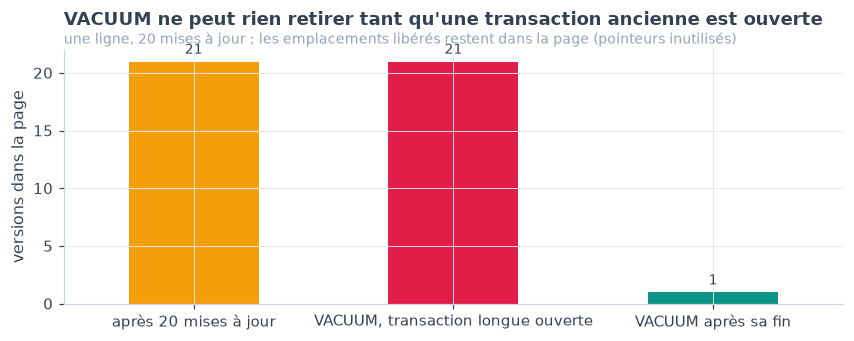

,versions_physiques,vivantes
après 20 mises à jour,21,1
"VACUUM, transaction longue ouverte",21,1
VACUUM après sa fin,1,1


In [5]:
admin("VACUUM mvcc")
longue = session("RR")
longue.execute("SELECT v FROM mvcc WHERE id = 1").fetchone()
for i in range(20):
    admin("UPDATE mvcc SET v = %s WHERE id = 1", (1000 + i,))


def compte_versions():
    p = page()
    return dict(versions_physiques=len(p.dropna(subset=["xmin"])), vivantes=int((p["état"] == "vivante").sum()))


etapes = {"après 20 mises à jour": compte_versions()}
admin("VACUUM mvcc")
etapes["VACUUM, transaction longue ouverte"] = compte_versions()
print("la transaction longue lit toujours :", longue.execute("SELECT v FROM mvcc WHERE id = 1").fetchone()[0])
longue.commit(); longue.close()
admin("VACUUM mvcc")
etapes["VACUUM après sa fin"] = compte_versions()
vac = pd.DataFrame(etapes).T
ax = vac["versions_physiques"].plot.bar(figsize=(8, 3.2), color=[AMBER, ROSE, TEAL], rot=0)
annotate_bars(ax, "{:.0f}")
ax.set_ylabel("versions dans la page")
ax.set_title("VACUUM ne peut rien retirer tant qu'une transaction ancienne est ouverte")
subtitle(ax, "une ligne, 20 mises à jour ; les emplacements libérés restent dans la page (pointeurs inutilisés)")
plt.tight_layout(); plt.show()
vac

Pendant que la transaction longue est ouverte, `VACUUM` conserve toutes les versions
(elle pourrait en avoir besoin selon l'horizon de PostgreSQL), et elle continue de lire
la valeur de son instantané. Une fois terminée, `VACUUM` retire toutes les versions
mortes. C'est le gonflement de table mesuré à l'exercice 7.3.

> **À retenir.** Dans PostgreSQL, une mise à jour écrit une nouvelle version ; les
> anciennes ne disparaissent qu'au `VACUUM`, et seulement si aucune transaction ouverte
> ne peut encore les voir.